# 04 · Calibration: can the probabilities be taken at face value? (H3)

ROC-AUC only checks the **ranking**. A lender also uses the probability itself (pricing, expected loss = PD × exposure),
so "20% risk" should mean that about 20 of 100 such clients default.

**Hypothesis H3 (written before training):** Random Forest probabilities are squeezed toward the middle;
logistic regression is well calibrated.

Everything here uses the **out-of-fold** predictions from notebook 02: each client's prediction comes from a model
that never saw that client.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

from src.data import load
from src.cv import folds
from src.viz import set_style, save, BLUE, ORANGE, AQUA, INK_2, GRID, SURFACE

set_style()
oof = pd.read_parquet("../data/processed/oof_baseline.parquet")
y = oof["TARGET"]
MODELS = {"LogReg (median + missing flags)": BLUE, "Random Forest": ORANGE, "LightGBM": AQUA}

## Reliability diagram
Sort clients by predicted risk, cut into 20 equal-size groups, and compare the **mean prediction** with the
**observed default rate** in each group. A well-calibrated model sits on the diagonal.

**ECE** (expected calibration error) = size-weighted mean of |predicted − observed| over the groups.

In [2]:
def reliability(p: pd.Series, y: pd.Series, n_bins: int = 20) -> pd.DataFrame:
    b = pd.qcut(p.rank(method="first"), n_bins, labels=False)
    return pd.DataFrame({"pred": p, "obs": y, "bin": b}).groupby("bin").agg(
        pred=("pred", "mean"), obs=("obs", "mean"), n=("obs", "size"))

def ece(p, y, n_bins: int = 20) -> float:
    r = reliability(pd.Series(p), pd.Series(y), n_bins)
    return float(np.sum(r.n * (r.pred - r.obs).abs()) / r.n.sum())

def scores(p, y) -> dict:
    return {"ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p),
            "LogLoss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "ECE": ece(p, y),
            "mean prediction": float(np.mean(p)), "max prediction": float(np.max(p))}

summary = pd.DataFrame({m: scores(oof[m], y) for m in MODELS}).T
summary.loc["observed default rate", "mean prediction"] = y.mean()
summary.style.format("{:.4f}", na_rep="")

,ROC-AUC,Brier,LogLoss,ECE,mean prediction,max prediction
LogReg (median + missing flags),0.7486,0.0685,0.2491,0.0021,0.0807,1.0000
Random Forest,0.7452,0.0693,0.2528,0.0170,0.0809,0.4077
LightGBM,0.7585,0.0679,0.2461,0.0037,0.0799,0.8513
observed default rate,,,,,0.0807,


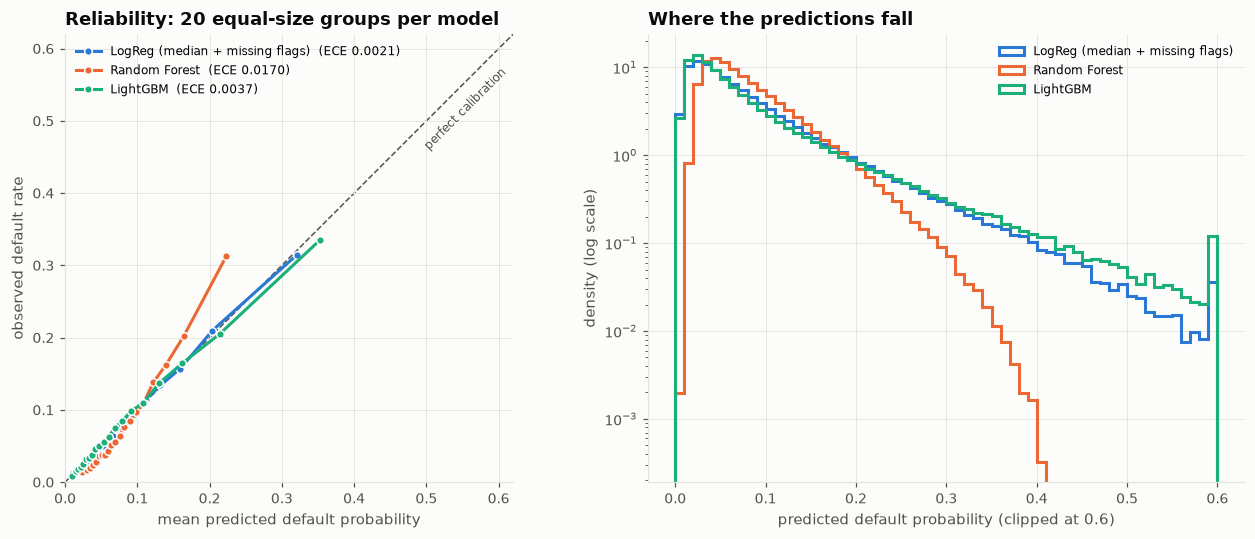

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
lim = 0.62
ax.plot([0, lim], [0, lim], color=INK_2, lw=1, ls="--", zorder=0)
ax.text(lim * 0.97, lim * 0.93, "perfect calibration", rotation=45, ha="right", va="top",
        color=INK_2, fontsize=8, rotation_mode="anchor")
for m, c in MODELS.items():
    r = reliability(oof[m], y)
    ax.plot(r.pred, r.obs, color=c, marker="o", markersize=5, markeredgecolor=SURFACE,
            markeredgewidth=1, label=f"{m}  (ECE {ece(oof[m], y):.4f})")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("mean predicted default probability")
ax.set_ylabel("observed default rate")
ax.set_title("Reliability: 20 equal-size groups per model")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
bins = np.linspace(0, 0.6, 61)
for m, c in MODELS.items():
    ax.hist(oof[m].clip(upper=0.6), bins=bins, histtype="step", lw=2, color=c, label=m, density=True)
ax.set_yscale("log")
ax.set_xlabel("predicted default probability (clipped at 0.6)")
ax.set_ylabel("density (log scale)")
ax.set_title("Where the predictions fall")
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "calibration_reliability")
plt.show()

## Why does logistic regression output 1.000 for some clients?

In [4]:
train = load("application_train", usecols=["SK_ID_CURR", "AMT_INCOME_TOTAL", "AMT_CREDIT", "TARGET"])
top = oof.nlargest(5, "LogReg (median + missing flags)")[["SK_ID_CURR", "LogReg (median + missing flags)",
                                                          "LightGBM", "Random Forest", "TARGET"]]
top = top.merge(train[["SK_ID_CURR", "AMT_INCOME_TOTAL", "AMT_CREDIT"]], on="SK_ID_CURR")
print(f"Median income in train: {train.AMT_INCOME_TOTAL.median():,.0f}   |   "
      f"99.9th percentile: {train.AMT_INCOME_TOTAL.quantile(0.999):,.0f}")
top.style.format({"LogReg (median + missing flags)": "{:.4f}", "LightGBM": "{:.4f}", "Random Forest": "{:.4f}",
                  "AMT_INCOME_TOTAL": "{:,.0f}", "AMT_CREDIT": "{:,.0f}"})

Median income in train: 147,150   |   99.9th percentile: 900,000


,SK_ID_CURR,LogReg (median + missing flags),LightGBM,Random Forest,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT
0,114967,1.0000,0.3631,0.2052,1,"117,000,000","562,491"
1,272071,0.9686,0.0617,0.0997,0,"202,500","180,000"
2,336147,0.9105,0.0136,0.0453,0,"18,000,090","675,000"
3,385674,0.7900,0.0398,0.0551,0,"13,500,000","1,400,504"
4,325842,0.7343,0.4936,0.3975,1,"135,000","407,727"


In logistic regression each feature adds **coefficient × scaled value** to the log-odds, so a single extreme value
can push the prediction to 0 or 1. Decompose the log-odds of the most extreme clients (model refit on all of train):

In [5]:
from src.features import application_features
from src.models import logreg

full = load("application_train")
Xf = application_features(full)
lr_model = logreg(missing_indicators=True).fit(Xf, full["TARGET"])
pre, lr = lr_model[0], lr_model[-1]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
rows = []
for cid in [114967, 272071, 336147]:
    i = full.index[full.SK_ID_CURR == cid][0]
    contrib = pd.Series(lr.coef_[0] * pre.transform(Xf.iloc[[i]])[0], index=names)
    for n, v in contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3).items():
        rows.append({"client": cid, "total log-odds": lr.intercept_[0] + contrib.sum(), "feature": n,
                     "contribution": v, "client value": Xf.iloc[i][n], "train median": Xf[n].median()})
pd.DataFrame(rows).set_index(["client", "total log-odds", "feature"]).style.format(
    {"contribution": "{:+.2f}", "client value": "{:,.2f}", "train median": "{:,.2f}"})

* Client 114967 reports an income of **117,000,000** (median 147,150; 99.9th percentile 900,000). One value, 800× the
  median, adds +28 to the log-odds on its own. (The client did default, so the extreme prediction is "right" by accident.)
* Client 272071 has 344–348 people in their "social circle" (median 0). `OBS_30_…` and `OBS_60_…` are almost the same
  column, so the model gives them large opposite coefficients (+5.1 / −5.4) that cancel for normal clients but not
  exactly at extreme values: a symptom of **collinearity**.
* Trees are immune: a split only asks "above or below a threshold", so 117M behaves like 1M. This is another reason
  logistic regression needs more preprocessing (clipping / log-transforming skewed amounts) than LightGBM.

## Can the Random Forest be fixed after the fact?
**Isotonic regression** learns a monotone map "raw prediction → observed rate". Because it never changes the order of
clients, ROC-AUC stays (almost) the same and only the probabilities move. To stay honest it is **cross-fitted** with the
same 5 folds: each fold is recalibrated with a map learned on the other four.

In [6]:
def cross_fit_isotonic(p: np.ndarray, y: np.ndarray) -> np.ndarray:
    out = np.zeros_like(p)
    for tr, va in folds(pd.Series(y)):
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p[tr], y[tr])
        out[va] = iso.predict(p[va])
    return out

rf_cal = cross_fit_isotonic(oof["Random Forest"].values, y.values)
before_after = pd.DataFrame({"Random Forest (raw)": scores(oof["Random Forest"], y),
                             "Random Forest (isotonic)": scores(rf_cal, y),
                             "LightGBM (raw)": scores(oof["LightGBM"], y)}).T
before_after.style.format("{:.4f}")

,ROC-AUC,Brier,LogLoss,ECE,mean prediction,max prediction
Random Forest (raw),0.7452,0.0693,0.2528,0.0170,0.0809,0.4077
Random Forest (isotonic),0.7443,0.0687,0.2500,0.0010,0.0807,0.8523
LightGBM (raw),0.7585,0.0679,0.2461,0.0037,0.0799,0.8513


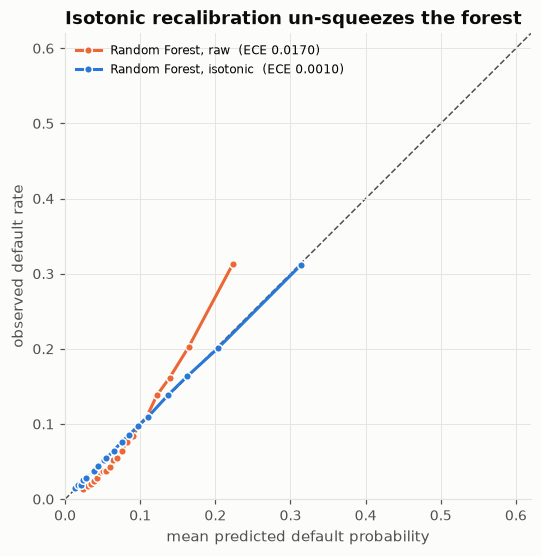

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, lim], [0, lim], color=INK_2, lw=1, ls="--", zorder=0)
for label, p, c in [("Random Forest, raw", oof["Random Forest"], ORANGE),
                    ("Random Forest, isotonic", pd.Series(rf_cal), BLUE)]:
    r = reliability(p, y)
    ax.plot(r.pred, r.obs, color=c, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1,
            label=f"{label}  (ECE {ece(p, y):.4f})")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("mean predicted default probability")
ax.set_ylabel("observed default rate")
ax.set_title("Isotonic recalibration un-squeezes the forest")
ax.legend(loc="upper left", fontsize=8)
save(fig, "calibration_rf_isotonic")
plt.show()

## Findings for H3
* **Held for Random Forest.** Its predictions never exceed 0.41 and the reliability curve is steeper than the diagonal:
  it **over-states risk for safe clients and under-states it for risky ones** (top group: predicted 22%, observed 31%).
  ECE 0.017, 5–8× worse than the other two.
* **Held for logistic regression** on average (ECE 0.002, best of the three), with a caveat: a handful of extreme
  inputs produce absurd probabilities (0.97–1.00).
* **LightGBM is also well calibrated** (ECE 0.004) out of the box: boosting with log-loss optimises probabilities directly.
* **The forest can be repaired.** Cross-fitted isotonic regression brings ECE from 0.017 to 0.001 and improves Brier and
  LogLoss while ROC-AUC barely moves (0.7452 → 0.7443). Ranking quality and probability quality are separate properties:
  a model can rank well and still need recalibration before its probabilities are used for pricing.